In [2]:
import sys
from pathlib import Path

# Pointer sur root de project
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np

from src.const import DATA_DIR, RANDOM_KEY
from src.data_loader import loead_images, convert_to_numpay_table
from src.visualization import afficher_images_echntillon, afficher_distribution_classes, afficher_images_augmentation, afficher_courbes_apprentissage
from src.preprocessing import applay_encoding
from src.dataset import create_dataset, load_image
from src.model import evaluate_model, build_cnn_model, build_transfer_model, set_model_alias
import src.mlflow_config

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers

Project root : /home/hajjajihamza/Ycode/brief-5
Tracking URI : sqlite:////home/hajjajihamza/Ycode/brief-5/mlflow/mlflow.db
Database : /home/hajjajihamza/Ycode/brief-5/mlflow/mlflow.db
Artifacts : file:///workspace/workspace/brief-5/mlflow/artifacts
Experiment ID : 1


#### Charger les images

In [2]:
images_path, labels = loead_images(DATA_DIR)


print("Nomber d'images :", len(images_path))
print("Nomber de labels :", len(labels))

print('Example de image:', images_path[0])
print('Example de Label:', labels[0])

Nomber d'images : 7023
Nomber de labels : 7023
Example de image: /root/.cache/kagglehub/datasets/karapy/neurovision/versions/1/Data/glioma/Te-glTr_0000.jpg
Example de Label: glioma


#### Convertir les listes en tableaux NumPy

In [3]:
X, y = convert_to_numpay_table(images_path, labels)

#### Afficher un échantillon d'images

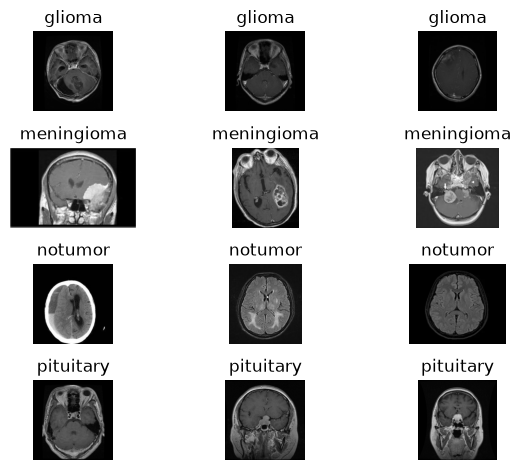

In [4]:
afficher_images_echntillon(X, y)

#### Afficher la distribution et l'équilibre des images

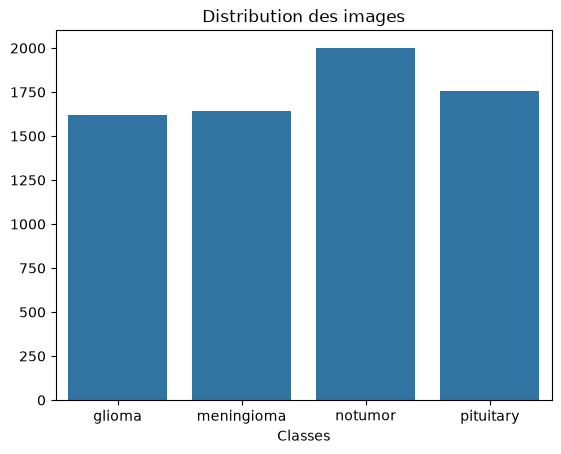

In [5]:
afficher_distribution_classes(y)

#### Appliquer Label Encoging 

In [6]:
y_encoder, label_encoder = applay_encoding(y)

print(len(np.unique(y_encoder)))

4


#### Split data

In [7]:
# Split test and train
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y_encoder, 
    test_size=0.3,
    stratify=y_encoder,
    random_state=RANDOM_KEY
)

# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,
    stratify=y_temp,
    random_state=RANDOM_KEY
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 3932
Validation : 984
Test : 2107


#### Appliquer One-Hot Encoding

In [8]:
num_classes = len(np.unique(y_encoder))
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)

#### Data augmentation

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

I0000 00:00:1793025148.913189  160987 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10262 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


#### Exemple des images avec augmentation

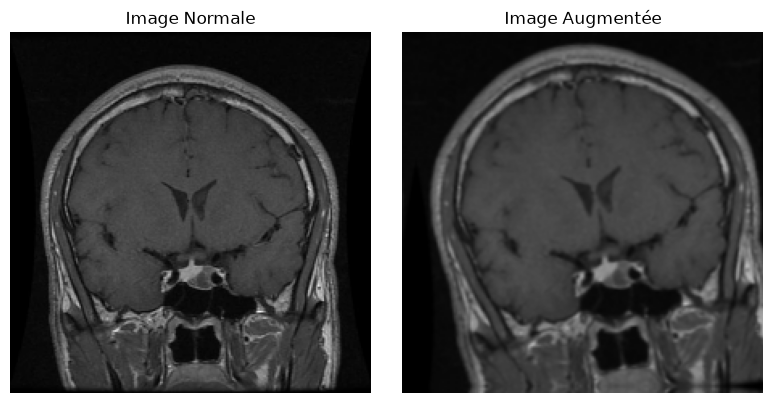

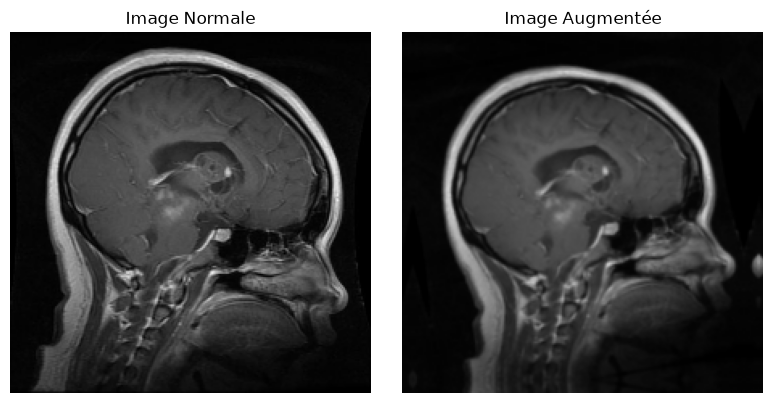

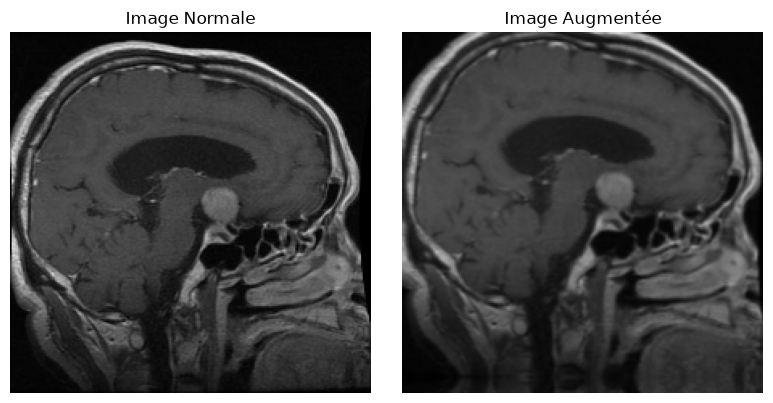

In [10]:
for i in range(3):
    afficher_images_augmentation(X_train[i], data_augmentation)

### CNN

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,476 (42.64 MB)

 Trainable params: 11,177,476 (42.64 MB)

 Non-trainable params: 0 (0.00 B)


========= Training =========

Epoch 1/45


/workspace/workspace/brief-5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1793025157.909154  160987 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1793025159.102080  161389 cuda_dnn.cc:461] Loaded cuDNN version 92700


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3558 - loss: 1.3337
Epoch 1: val_loss improved from None to 1.02318, saving model to ../output/models/cnn/best_model_cnn.keras

Epoch 1: finished saving model to ../output/models/cnn/best_model_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - accuracy: 0.3558 - loss: 1.3337 - val_accuracy: 0.5833 - val_loss: 1.0232
Epoch 2/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5568 - loss: 1.0287
Epoch 2: val_loss improved from 1.02318 to 0.83705, saving model to ../output/models/cnn/best_model_cnn.keras

Epoch 2: finished saving model to ../output/models/cnn/best_model_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.5565 - loss: 1.0297 - val_accuracy: 0.6565 - val_loss: 0.8371
Epoch 3/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.6506 - loss: 0.8564
Epoch 3: val_loss improved from 0.83705 to 0.63031, saving model to ../output/models/cnn/best_model_cnn.keras

Epoch 3: finished saving model to ../out

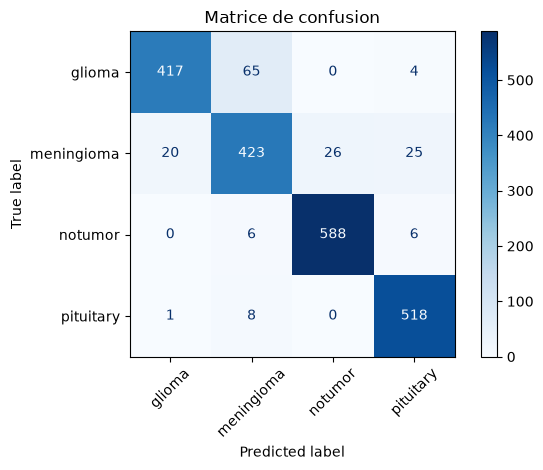

2026/10/26 14:38:31 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.95      0.86      0.90       486
  meningioma       0.84      0.86      0.85       494
     notumor       0.96      0.98      0.97       600
   pituitary       0.94      0.98      0.96       527

    accuracy                           0.92      2107
   macro avg       0.92      0.92      0.92      2107
weighted avg       0.92      0.92      0.92      2107



2026/10/26 14:38:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'cnn'.
Created version '1' of model 'cnn'.


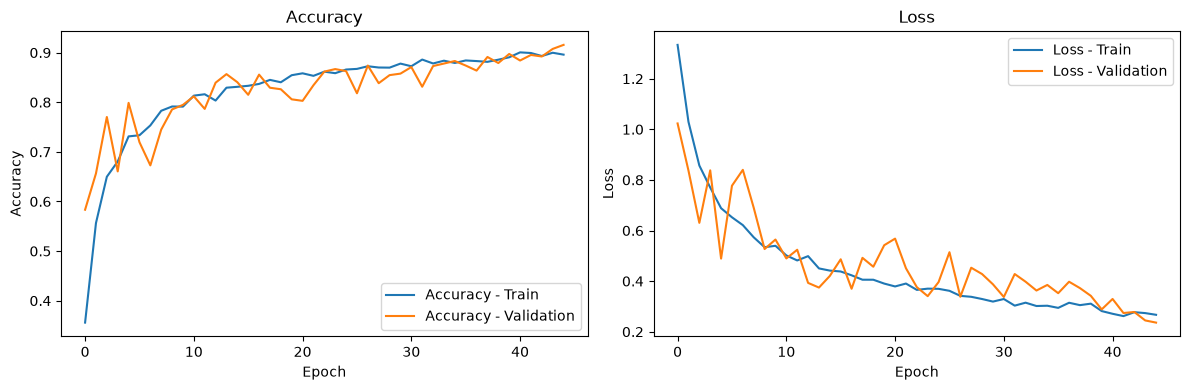

In [11]:
build_cnn_model(
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test,
    data_augmentation=data_augmentation,
    label_encoder=label_encoder
)

#### MobileNetV2

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (1, 7, 7, 1280)        │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 1280)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 128)               │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (1, 4)                 │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


========= Tresfer Learning =========

Epoch 1/45


/workspace/workspace/brief-5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7683 - loss: 0.6034
Epoch 1: val_loss improved from None to 0.48140, saving model to ../output/models/mobilenetv2_1_00_224/best_model_tl.keras

Epoch 1: finished saving model to ../output/models/mobilenetv2_1_00_224/best_model_tl.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.7683 - loss: 0.6034 - val_accuracy: 0.8028 - val_loss: 0.4814
Epoch 2/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8608 - loss: 0.3773
Epoch 2: val_loss did not improve from 0.48140
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.8609 - loss: 0.3773 - val_accuracy: 0.8049 - val_loss: 0.4992
Epoch 3/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8825 - loss: 0.3206
Epoch 3: val_loss did not improve from 0.48140
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.8822 - loss: 0.3214 - val_accuracy: 0.7947 - val_loss: 0.5534
Epoch 4/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8945 - loss: 0.2739
Epoch 4: va

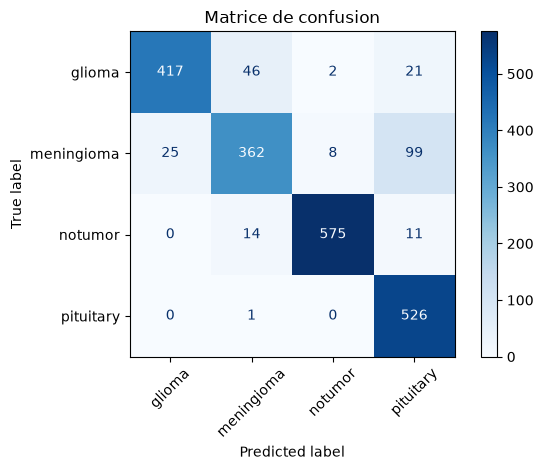

2026/10/26 14:44:21 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.94      0.86      0.90       486
  meningioma       0.86      0.73      0.79       494
     notumor       0.98      0.96      0.97       600
   pituitary       0.80      1.00      0.89       527

    accuracy                           0.89      2107
   macro avg       0.90      0.89      0.89      2107
weighted avg       0.90      0.89      0.89      2107



2026/10/26 14:44:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'mobilenetv2_1_00_224_transfer_learning'.
Created version '1' of model 'mobilenetv2_1_00_224_transfer_learning'.


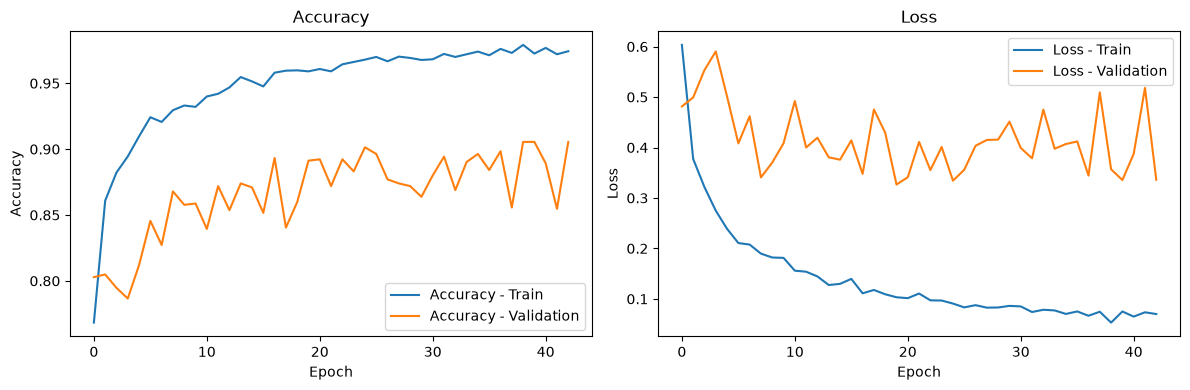


========= Fine Tuning =========

Epoch 1/45


/workspace/workspace/brief-5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9626 - loss: 0.0963
Epoch 1: val_loss improved from None to 0.38215, saving model to ../output/models/mobilenetv2_1_00_224/best_model_ft.keras

Epoch 1: finished saving model to ../output/models/mobilenetv2_1_00_224/best_model_ft.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.9626 - loss: 0.0963 - val_accuracy: 0.8831 - val_loss: 0.3822
Epoch 2/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9678 - loss: 0.0847
Epoch 2: val_loss improved from 0.38215 to 0.35752, saving model to ../output/models/mobilenetv2_1_00_224/best_model_ft.keras

Epoch 2: finished saving model to ../output/models/mobilenetv2_1_00_224/best_model_ft.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step - accuracy: 0.9680 - loss: 0.0844 - val_accuracy: 0.8831 - val_loss: 0.3575
Epoch 3/45
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9716 - loss: 0.0805
Epoch 3: val_loss did not improve from 0.35752
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step

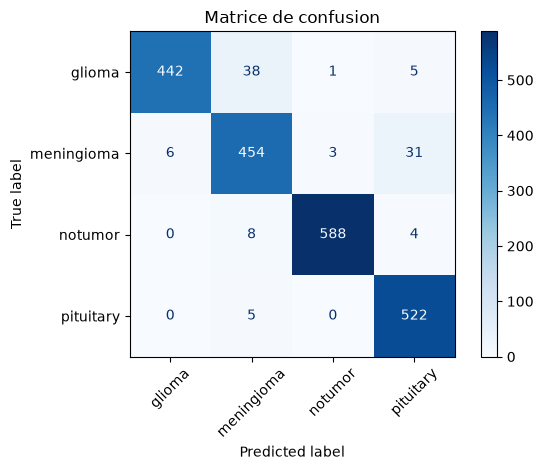

2026/10/26 14:51:17 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


              precision    recall  f1-score   support

      glioma       0.99      0.91      0.95       486
  meningioma       0.90      0.92      0.91       494
     notumor       0.99      0.98      0.99       600
   pituitary       0.93      0.99      0.96       527

    accuracy                           0.95      2107
   macro avg       0.95      0.95      0.95      2107
weighted avg       0.95      0.95      0.95      2107



2026/10/26 14:51:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'mobilenetv2_1_00_224_fine_tuning'.
Created version '1' of model 'mobilenetv2_1_00_224_fine_tuning'.


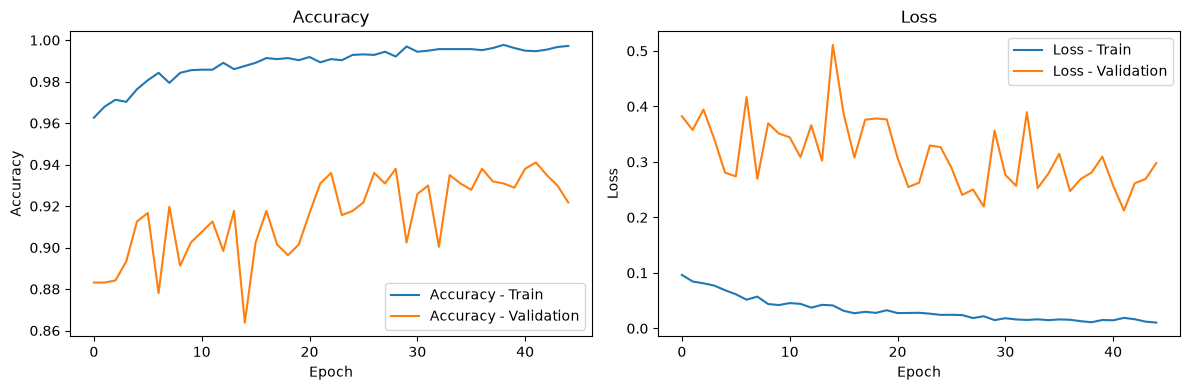

In [12]:
build_transfer_model(
    base_model=MobileNetV2,
    normalize_collback=preprocess_input,
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test,
    data_augmentation=data_augmentation,
    label_encoder=label_encoder
)


#### Champion

In [3]:
model_name = "mobilenetv2_1_00_224_fine_tuning"
model_version = "1"
set_model_alias(model_name, model_version)